
# Bank Marketing Subscription Prediction
### End-to-end classification with chronological validation

**Business question.** Can information available before a customer call help a bank prioritize outreach to customers who may subscribe to a term deposit?

This project uses UCI's full Bank Marketing dataset, compares a transparent baseline with logistic regression and random forest, tunes logistic regression, and evaluates on the latest 20% of the source rows. UCI states that `bank-additional-full.csv` is ordered by date from May 2008 to November 2010. Because an exact contact-date column is not included in the file, row order is used as a chronological proxy. The notebook also uses expanding-window cross-validation; it does not shuffle records.

| Project element | Choice |
|:--|:--|
| Problem type | Binary classification |
| Target | `y` — term-deposit subscription (`yes` / `no`) |
| Data | UCI Bank Marketing, `bank-additional-full.csv` |
| Validation | Latest 20% of ordered rows as holdout; expanding-window 5-fold CV on earlier rows |
| Primary comparison metric | ROC-AUC, alongside average precision, balanced accuracy, precision, recall, and F1 |

> **Important modeling choice:** call duration is only known after a call. It is shown in EDA to demonstrate leakage, then excluded from every model. The current-campaign contact count is retained only under the assumption that the next attempt number is known before making that call; revisit it if the scoring decision happens earlier.

**Learning path:** inspect the data → ask questions with EDA → prepare features → establish a baseline → compare models over time → tune → evaluate → communicate findings.

**Before sharing:** run all cells from top to bottom to generate fresh plots and metrics. The outputs from the previous random-split version were removed so they cannot be confused with this chronological evaluation.



## 1. Setup

The notebook uses only common Python data-science packages. A fixed random seed controls randomized estimators. The chronological split and expanding-window folds are deterministic and preserve the source order. The data download needs an internet connection when you run the notebook.


In [30]:

from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    ConfusionMatrixDisplay,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    RocCurveDisplay,
)
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 120)
plt.style.use("seaborn-v0_8-whitegrid")



## 2. Load the real dataset

The full data file is distributed inside the official UCI ZIP archive. The code downloads the archive in memory, opens the nested `bank-additional.zip`, and reads `bank-additional-full.csv` with its semicolon delimiter. No local data preparation or extra download package is required. Keep the original row order: UCI documents the full file as ordered by date.


In [31]:
DATA_URL = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"

with urlopen(DATA_URL, timeout=60) as response:
    archive_bytes = response.read()

with ZipFile(BytesIO(archive_bytes)) as outer_zip:
    nested_archive_name = next(
        name for name in outer_zip.namelist()
        if name.lower().endswith("bank-additional.zip")
    )
    with ZipFile(BytesIO(outer_zip.read(nested_archive_name))) as data_zip:
        csv_name = next(
            name for name in data_zip.namelist()
            if name.lower().endswith("bank-additional-full.csv")
        )
        with data_zip.open(csv_name) as csv_file:
            df = pd.read_csv(csv_file, sep=";")

print(f"Dataset loaded: {df.shape[0]:,} rows × {df.shape[1]:,} columns")
df.head()

Dataset loaded: 41,188 rows × 21 columns


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 3. Understand the table

Start with the shape, column types, sample rows, and target balance. The positive class is usually much smaller than the negative class, so accuracy alone can give a misleading impression of model quality.

In [32]:
print("Shape:", df.shape)
print("\nColumn types:")
display(df.dtypes.value_counts().rename_axis("dtype").to_frame("number of columns"))
print("\nTarget counts:")
display(df["y"].value_counts().rename("customers").to_frame())
print("\nTarget share:")
display((df["y"].value_counts(normalize=True) * 100).round(2).rename("percent").to_frame())

Shape: (41188, 21)

Column types:


,number of columns
dtype,
object,11
int64,5
float64,5



Target counts:


,customers
y,
no,36548
yes,4640



Target share:


,percent
y,
no,88.73
yes,11.27


In [33]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 


## 4. Data quality checks

UCI describes the dataset as having no missing values, but we verify that claim locally. The literal value `unknown` is a recorded category, not an empty cell, so we keep it as a category. Exact duplicate rows are counted but retained: without a customer or contact ID, an identical row is not enough to prove that it is an accidental export duplicate rather than a valid observation. The duplicate count is tiny, but the choice is documented rather than automatic.


In [34]:

missing = df.isna().sum().sort_values(ascending=False)
print("Missing values by column:")
display(missing[missing.gt(0)].rename("missing rows").to_frame())
duplicate_count = int(df.duplicated().sum())
print(f"Exact duplicate rows: {duplicate_count:,} of {len(df):,}")
print("Literal 'unknown' counts in categorical columns:")
unknown_counts = df.select_dtypes(include="object").eq("unknown").sum().sort_values(ascending=False)
display(unknown_counts[unknown_counts.gt(0)].rename("unknown values").to_frame())


Missing values by column:


,missing rows


Exact duplicate rows: 12 of 41,188
Literal 'unknown' counts in categorical columns:


,unknown values
default,8597
education,1731
housing,990
loan,990
job,330
marital,80


In [35]:

print(f"Retaining all {len(df):,} source rows and their original order for chronological validation.")


Retaining all 41,188 source rows and their original order for chronological validation.


## 5. Exploratory data analysis

These plots answer practical questions: how imbalanced is the target, how does subscription rate vary across customer and campaign groups, and which relationships need special care? The charts show historical associations; they do not prove that any characteristic causes a subscription.

### 5.1 Target balance

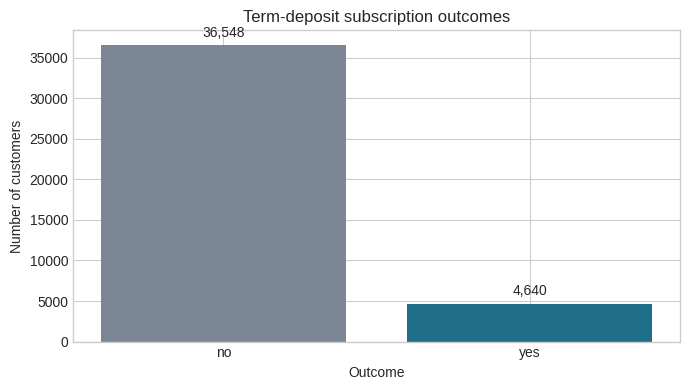

In [36]:
target_counts = df["y"].value_counts().reindex(["no", "yes"])
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(target_counts.index, target_counts.values, color=["#7b8794", "#1f6f8b"])
ax.set(title="Term-deposit subscription outcomes", xlabel="Outcome", ylabel="Number of customers")
ax.bar_label(bars, labels=[f"{value:,}" for value in target_counts.values], padding=4)
fig.tight_layout()
plt.show()

### 5.2 Customer age

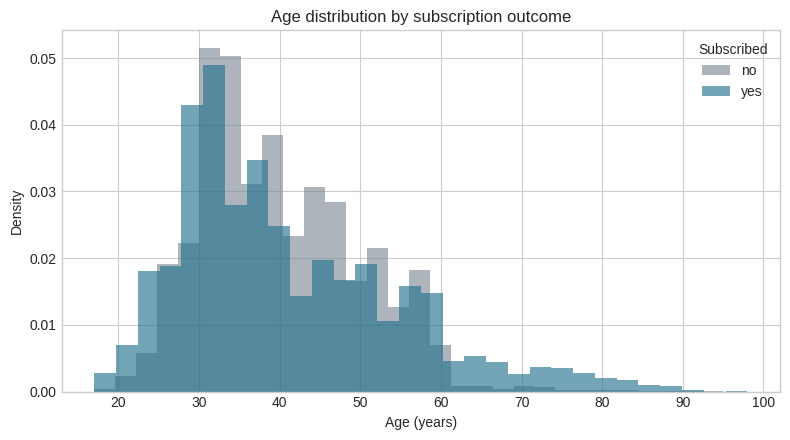

In [37]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for outcome, color in [("no", "#7b8794"), ("yes", "#1f6f8b")]:
    ax.hist(df.loc[df["y"].eq(outcome), "age"], bins=30, alpha=0.62,
            density=True, label=outcome, color=color)
ax.set(title="Age distribution by subscription outcome", xlabel="Age (years)", ylabel="Density")
ax.legend(title="Subscribed")
fig.tight_layout()
plt.show()

### 5.3 Subscription rate by month

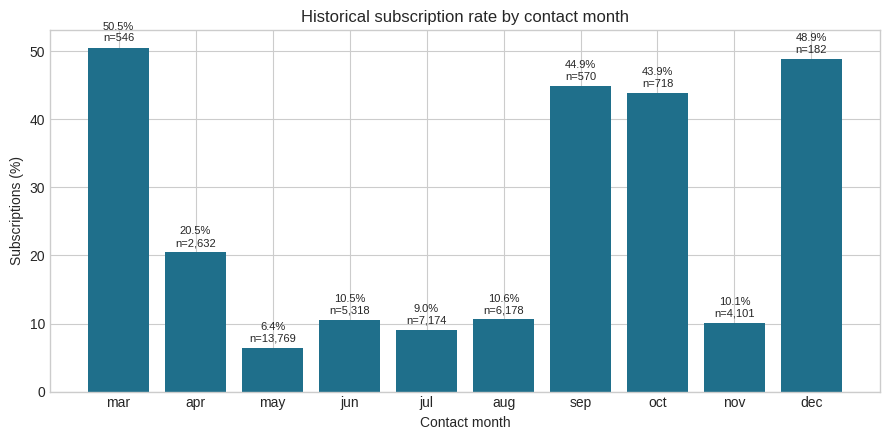

In [38]:

month_order = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
month_summary = df.groupby("month", observed=True)["y"].agg(
    subscription_rate=lambda s: s.eq("yes").mean(), customers="size"
)
month_summary = month_summary.reindex([m for m in month_order if m in month_summary.index])
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(month_summary.index, month_summary["subscription_rate"] * 100, color="#1f6f8b")
ax.set(title="Historical subscription rate by contact month", xlabel="Contact month", ylabel="Subscriptions (%)")
ax.bar_label(bars, labels=[f"{rate:.1f}%\nn={count:,}" for rate, count in zip(
    month_summary["subscription_rate"] * 100, month_summary["customers"]
)], padding=3, fontsize=8)
fig.tight_layout()
plt.show()


### 5.4 Subscription rate by previous campaign outcome

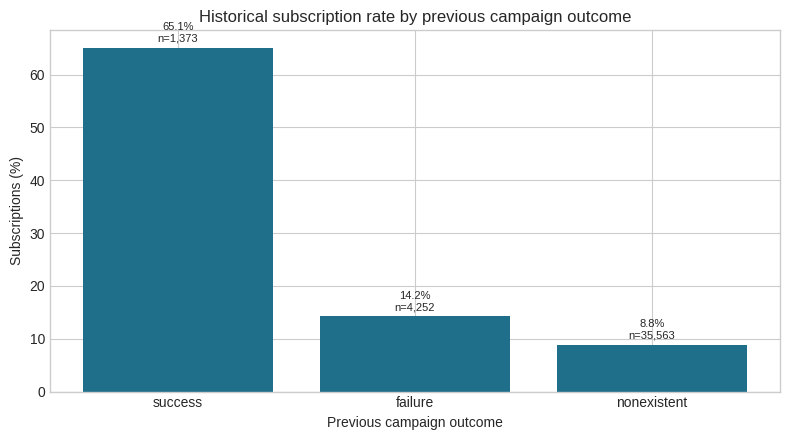

In [39]:

previous_summary = df.groupby("poutcome", observed=True)["y"].agg(
    subscription_rate=lambda s: s.eq("yes").mean(), customers="size"
).sort_values("subscription_rate", ascending=False)
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(previous_summary.index, previous_summary["subscription_rate"] * 100, color="#1f6f8b")
ax.set(title="Historical subscription rate by previous campaign outcome",
       xlabel="Previous campaign outcome", ylabel="Subscriptions (%)")
ax.bar_label(bars, labels=[f"{rate:.1f}%\nn={count:,}" for rate, count in zip(
    previous_summary["subscription_rate"] * 100, previous_summary["customers"]
)], padding=3, fontsize=8)
fig.tight_layout()
plt.show()


### 5.5 Subscription rate by contact count in the current campaign

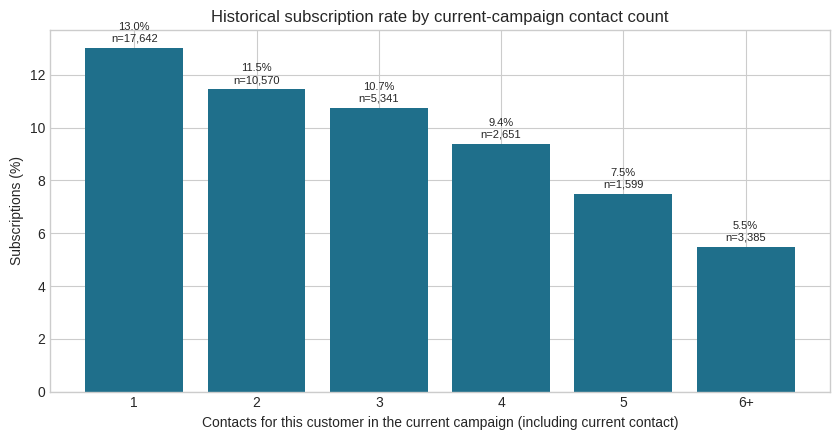

In [40]:
campaign_bins = pd.cut(
    df["campaign"], bins=[0, 1, 2, 3, 4, 5, np.inf],
    labels=["1", "2", "3", "4", "5", "6+"], right=True
)
campaign_summary = df.assign(contact_group=campaign_bins).groupby("contact_group", observed=False)["y"].agg(
    subscription_rate=lambda s: s.eq("yes").mean(), customers="size"
)
fig, ax = plt.subplots(figsize=(8.5, 4.5))
bars = ax.bar(campaign_summary.index.astype(str), campaign_summary["subscription_rate"] * 100,
              color="#1f6f8b")
ax.set(title="Historical subscription rate by current-campaign contact count",
       xlabel="Contacts for this customer in the current campaign (including current contact)",
       ylabel="Subscriptions (%)")
ax.bar_label(bars, labels=[f"{rate:.1f}%\nn={count:,}" for rate, count in zip(
    campaign_summary["subscription_rate"] * 100, campaign_summary["customers"]
)], padding=3, fontsize=8)
fig.tight_layout()
plt.show()

### 5.6 Call duration and target leakage

Duration can look highly predictive because it is measured while the call is happening and may reflect the conversation itself. A model used to prioritize whom to call cannot know this value in advance. We plot it to illustrate the relationship, then exclude it from the feature matrix below.

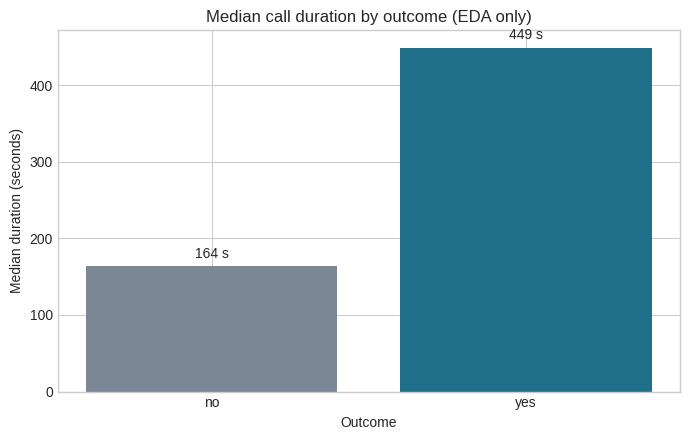

In [41]:
duration_summary = df.groupby("y", observed=True)["duration"].median().reindex(["no", "yes"])
fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(duration_summary.index, duration_summary.values, color=["#7b8794", "#1f6f8b"])
ax.set(title="Median call duration by outcome (EDA only)", xlabel="Outcome", ylabel="Median duration (seconds)")
ax.bar_label(bars, fmt="%.0f s", padding=4)
fig.tight_layout()
plt.show()

### 5.7 Numeric feature correlations

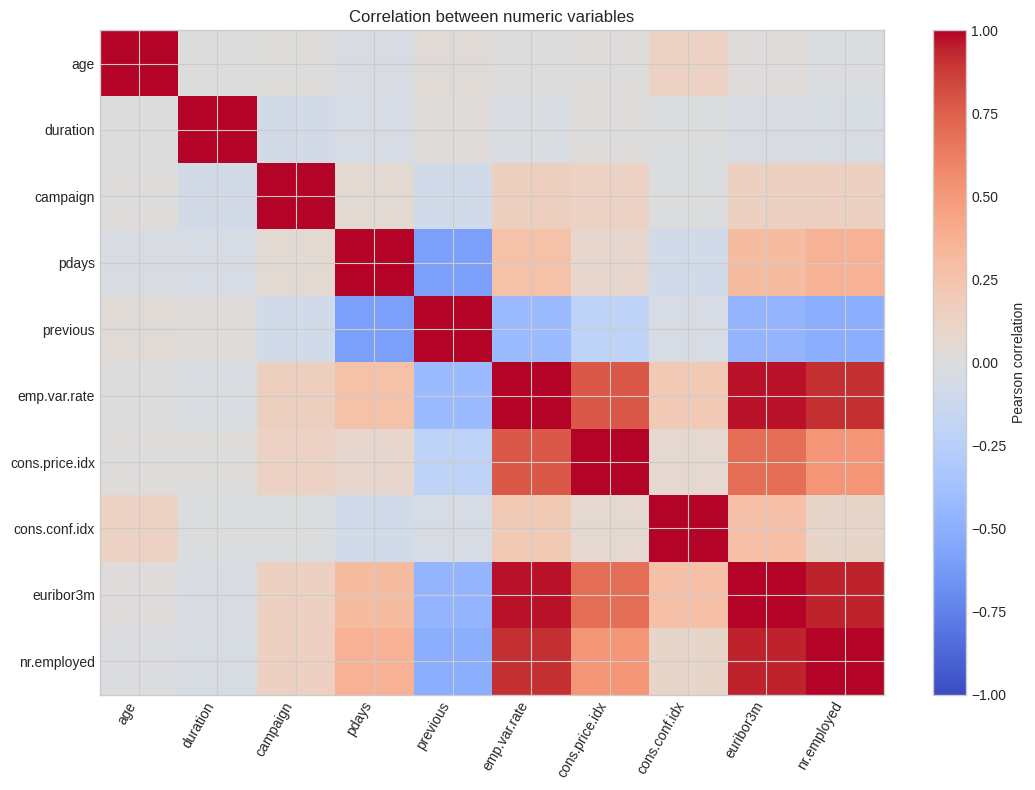

In [42]:
numeric_for_corr = df.select_dtypes(include=np.number)
corr = numeric_for_corr.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(11, 8))
image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=60, ha="right")
ax.set_yticks(range(len(corr.columns)), corr.columns)
ax.set_title("Correlation between numeric variables")
fig.colorbar(image, ax=ax, label="Pearson correlation")
fig.tight_layout()
plt.show()


## 6. Prepare features and target

We use the remaining columns to predict `y`. The UCI `pdays` field uses `999` as a special code for “not previously contacted”; it does not mean 999 actual days. We create two signals: whether a previous contact occurred and the number of days when one did. Numeric imputation is fitted within each training fold.

`duration` is removed because the use case is a prediction before the call. `y` is encoded as `1 = yes` and `0 = no`. The source row order is preserved for the chronological split and is never given to the model as a feature.


In [43]:

model_df = df.copy()
model_df["was_previously_contacted"] = model_df["pdays"].ne(999).astype("int8")
model_df["days_since_previous_contact"] = model_df["pdays"].replace(999, np.nan)
model_df = model_df.drop(columns=["pdays"])

X = model_df.drop(columns=["y", "duration"])
y = model_df["y"].map({"no": 0, "yes": 1}).astype("int8")

print(f"Features: {X.shape[1]} | Rows: {X.shape[0]:,}")
print(f"Positive class share: {y.mean():.1%}")
print("Duration included in X?", "duration" in X.columns)
display(X.head())


Features: 20 | Rows: 41,188
Positive class share: 11.3%
Duration included in X? False


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,was_previously_contacted,days_since_previous_contact
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,NaN
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,NaN
2,37,services,married,high.school,no,yes,no,telephone,may,mon,1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,NaN
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,NaN
4,56,services,married,high.school,no,no,yes,telephone,may,mon,1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,NaN



## 7. Hold out the latest 20% and create a baseline

The file is ordered by date according to UCI, so we train on the first 80% and reserve the latest 20% of source rows as a time-ordered holdout. This is more realistic than a shuffled split, though it is only a proxy because the file has no explicit contact date. Class prevalence may shift across the boundary; we report both shares instead of forcing stratification.

A `most_frequent` dummy classifier provides a simple reference. Because the target is imbalanced, compare balanced accuracy, recall, and precision as well as accuracy.


In [44]:

test_fraction = 0.20
split_index = int(len(X) * (1 - test_fraction))
X_train, X_test = X.iloc[:split_index].copy(), X.iloc[split_index:].copy()
y_train, y_test = y.iloc[:split_index].copy(), y.iloc[split_index:].copy()

print(f"Earlier training rows: {len(X_train):,} (source rows 0–{split_index - 1:,})")
print(f"Latest test rows:      {len(X_test):,} (source rows {split_index:,}–{len(X) - 1:,})")
print(f"Positive share — train: {y_train.mean():.1%} | latest test: {y_test.mean():.1%}")


Earlier training rows: 32,950 (source rows 0–32,949)
Latest test rows:      8,238 (source rows 32,950–41,187)
Positive share — train: 6.4% | latest test: 30.8%


In [45]:

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_prediction = baseline.predict(X_test)
baseline_metrics = {
    "Accuracy": accuracy_score(y_test, baseline_prediction),
    "Balanced accuracy": balanced_accuracy_score(y_test, baseline_prediction),
    "Precision": precision_score(y_test, baseline_prediction, zero_division=0),
    "Recall": recall_score(y_test, baseline_prediction, zero_division=0),
    "F1": f1_score(y_test, baseline_prediction, zero_division=0),
}
baseline_results = pd.Series(
    baseline_metrics,
    name="Majority-class baseline",
).to_frame().round(3)

baseline_results


,Majority-class baseline
Accuracy,0.692
Balanced accuracy,0.500
Precision,0.000
Recall,0.000
F1,0.000



## 8. Build leakage-safe preprocessing pipelines

Imputers, scaling, and one-hot encoding live inside scikit-learn pipelines. Each chronological training fold fits its own preprocessing, preventing validation-fold information from leaking into the transform. Unknown categories at prediction time are safely ignored.


In [46]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

numeric_preprocessor = Pipeline(steps=[
    (
        "imputer",
        SimpleImputer(
            strategy="median",
            add_indicator=True,
            keep_empty_features=True,
        ),
    ),
    ("scaler", StandardScaler()),
])

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    (
        "onehot",
        OneHotEncoder(
            handle_unknown="infrequent_if_exist",
            min_frequency=10,
        ),
    ),
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_preprocessor, numeric_features),
    ("categorical", categorical_preprocessor, categorical_features),
])

logistic_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    (
        "model",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            solver="liblinear",
            random_state=RANDOM_STATE,
        ),
    ),
])

forest_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    (
        "model",
        RandomForestClassifier(
            n_estimators=120,
            min_samples_leaf=2,
            class_weight="balanced_subsample",
            n_jobs=1,
            random_state=RANDOM_STATE,
        ),
    ),
])


## 9. Compare models with expanding-window 5-fold cross-validation

`TimeSeriesSplit` preserves the source order: each validation fold occurs after its training fold, and later training folds expand to include more history. This mirrors forward prediction better than shuffling. We report fold mean and standard deviation for ROC-AUC, average precision, balanced accuracy, precision, recall, and F1. The threshold metrics use each classifier's default 0.50 cutoff and are not business-optimized.


In [47]:
cv = TimeSeriesSplit(n_splits=5)
cv_splits = list(cv.split(X_train))

fold_details = pd.DataFrame([
    {
        "Fold": fold_number,
        "Training rows": len(train_idx),
        "Validation rows": len(valid_idx),
        "Training positive share": y_train.iloc[train_idx].mean(),
        "Validation positive share": y_train.iloc[valid_idx].mean(),
    }
    for fold_number, (train_idx, valid_idx) in enumerate(cv_splits, start=1)
])

display(fold_details.round(3))

scoring = {
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
    "balanced_accuracy": "balanced_accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
}

cv_rows = []

for model_name, estimator in [
    ("Logistic regression", logistic_pipeline),
    ("Random forest", forest_pipeline),
]:
    scores = cross_validate(
        estimator=estimator,
        X=X_train,
        y=y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=False,
        n_jobs=1,
        error_score="raise",
    )

    row = {"Model": model_name}

    for metric in scoring:
        metric_name = metric.replace("_", " ").title()
        row[f"{metric_name} mean"] = scores[f"test_{metric}"].mean()
        row[f"{metric_name} std"] = scores[f"test_{metric}"].std()

    cv_rows.append(row)

cv_results = pd.DataFrame(cv_rows).set_index("Model")
display(cv_results.round(3))

,Fold,Training rows,Validation rows,Training positive share,Validation positive share
0,1,5495,5491,0.029,0.039
1,2,10986,5491,0.034,0.060
2,3,16477,5491,0.043,0.059
3,4,21968,5491,0.047,0.054
4,5,27459,5491,0.048,0.140


,Roc Auc mean,Roc Auc std,Average Precision mean,Average Precision std,Balanced Accuracy mean,Balanced Accuracy std,Precision mean,Precision std,Recall mean,Recall std,F1 mean,F1 std
Model,,,,,,,,,,,,
Logistic regression,0.520,0.064,0.083,0.060,0.492,0.029,0.072,0.042,0.619,0.300,0.087,0.024
Random forest,0.513,0.052,0.080,0.056,0.500,0.001,0.040,0.050,0.002,0.002,0.003,0.005



## 10. Tune logistic regression

Tune regularization strength `C` using the same expanding-window folds and ROC-AUC selection metric. Smaller `C` means stronger regularization. The best estimator is refit on all earlier training rows. The latest 20% test period is untouched until final evaluation.


In [48]:
param_grid = {"model__C": [0.1, 1.0, 10.0]}
search = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=1,
    refit=True,
    return_train_score=False,
)
search.fit(X_train, y_train)

print("Best C:", search.best_params_["model__C"])
print("Best mean CV ROC-AUC:", f"{search.best_score_:.3f}")
display(pd.DataFrame(search.cv_results_)[["param_model__C", "mean_test_score", "std_test_score"]]
        .rename(columns={"param_model__C": "C", "mean_test_score": "mean CV ROC-AUC", "std_test_score": "CV standard deviation"})
        .round(3))

Best C: 10.0
Best mean CV ROC-AUC: 0.522


,C,mean CV ROC-AUC,CV standard deviation
0,0.1,0.519,0.065
1,1.0,0.520,0.064
2,10.0,0.522,0.063



## 11. Evaluate once on the latest time-ordered test period

Report ROC-AUC and average precision from scores, plus threshold metrics at 0.50. Since the model uses class weights and probabilities have not been calibrated, 0.50 is an illustrative cutoff—not a claim that predicted scores are calibrated subscription probabilities. Choose an operational threshold using outreach capacity and the costs of missed subscribers versus additional calls, using training-period validation only.


In [49]:

final_model = search.best_estimator_
test_probability = final_model.predict_proba(X_test)[:, 1]
test_prediction = (test_probability >= 0.5).astype("int8")

test_metrics = {
    "Accuracy": accuracy_score(y_test, test_prediction),
    "Balanced accuracy": balanced_accuracy_score(y_test, test_prediction),
    "Precision": precision_score(y_test, test_prediction, zero_division=0),
    "Recall": recall_score(y_test, test_prediction, zero_division=0),
    "F1": f1_score(y_test, test_prediction, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_probability),
    "Average precision": average_precision_score(y_test, test_probability),
}
test_metrics = pd.Series(test_metrics, name="Latest-period test score")
display(test_metrics.to_frame().round(3))

print("Model versus simple baseline:")
comparison = pd.DataFrame({
    "Majority-class baseline": pd.Series(baseline_metrics),
    "Tuned logistic regression": test_metrics,
}).T
display(comparison.round(3))


,Latest-period test score
Accuracy,0.498
Balanced accuracy,0.585
Precision,0.361
Recall,0.811
F1,0.499
ROC-AUC,0.685
Average precision,0.495


Model versus simple baseline:


,Accuracy,Average precision,Balanced accuracy,F1,Precision,ROC-AUC,Recall
Majority-class baseline,0.692,NaN,0.500,0.000,0.000,NaN,0.000
Tuned logistic regression,0.498,0.495,0.585,0.499,0.361,0.685,0.811


### Confusion matrix and ROC curve

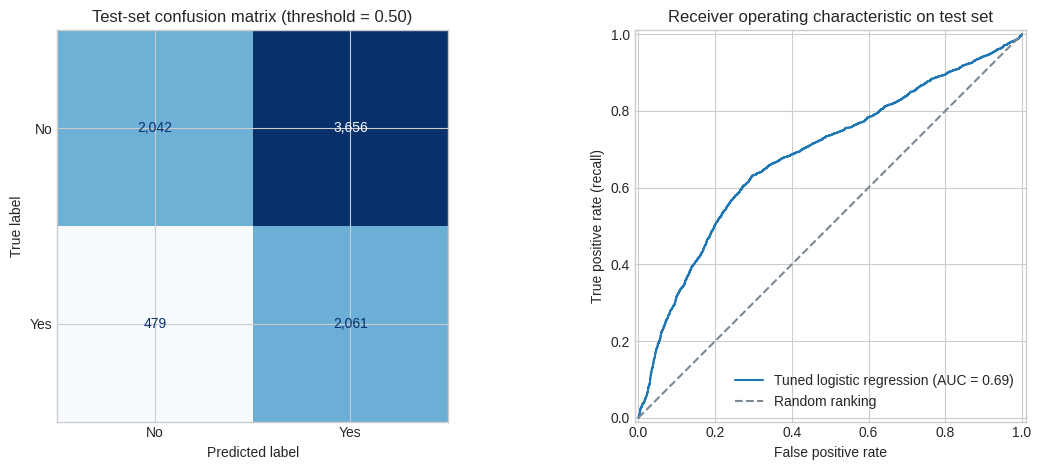

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

cm = confusion_matrix(y_test, test_prediction, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=["No", "Yes"]).plot(
    ax=axes[0], cmap="Blues", colorbar=False, values_format=",d"
)
axes[0].set_title("Test-set confusion matrix (threshold = 0.50)")

RocCurveDisplay.from_predictions(y_test, test_probability, ax=axes[1], name="Tuned logistic regression")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="#7b8794", label="Random ranking")
axes[1].set_title("Receiver operating characteristic on test set")
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate (recall)")
axes[1].legend(loc="lower right")

fig.tight_layout()
plt.show()


## 12. Interpret the fitted logistic regression

The encoder drops the first sorted category in each categorical feature, so each category coefficient is a contrast with that feature's displayed reference category. Numeric coefficients are per standardized unit. If a category appears in the later test period but not the training period, `handle_unknown="ignore"` maps it to all zeros (the same code as the dropped reference); the cell reports fitted reference categories, so interpret such cases cautiously. These values describe model associations, not causal effects, and can shift across time periods.


,reference category (dropped)
feature,
job,admin.
marital,divorced
education,basic.4y
default,no
housing,no
loan,no
contact,cellular
month,apr
day_of_week,fri


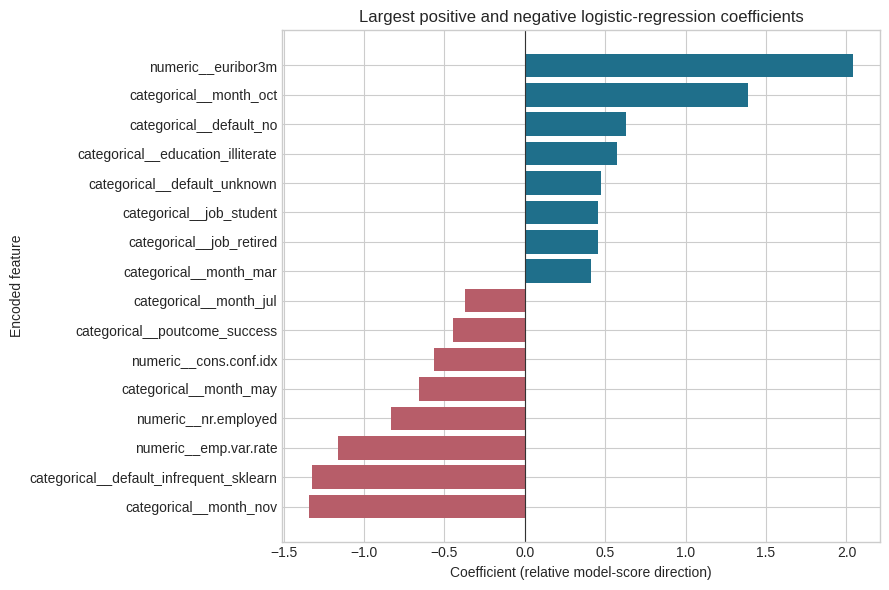

,coefficient
feature,
categorical__month_nov,-1.339
categorical__default_infrequent_sklearn,-1.321
numeric__emp.var.rate,-1.164
numeric__nr.employed,-0.833
categorical__month_may,-0.660
numeric__cons.conf.idx,-0.566
categorical__poutcome_success,-0.448
categorical__month_jul,-0.371
categorical__month_mar,0.412


In [51]:

fitted_preprocessor = final_model.named_steps["preprocessor"]
fitted_logistic = final_model.named_steps["model"]
feature_names = fitted_preprocessor.get_feature_names_out()
coefficients = pd.Series(fitted_logistic.coef_.ravel(), index=feature_names, name="coefficient")
top_coefficients = pd.concat([
    coefficients.nlargest(8).rename_axis("feature").reset_index(),
    coefficients.nsmallest(8).rename_axis("feature").reset_index(),
]).drop_duplicates("feature").sort_values("coefficient")

fitted_encoder = fitted_preprocessor.named_transformers_["categorical"].named_steps["onehot"]
reference_categories = pd.DataFrame({
    "feature": categorical_features,
    "reference category (dropped)": [categories[0] for categories in fitted_encoder.categories_],
}).set_index("feature")
display(reference_categories)

fig, ax = plt.subplots(figsize=(9, 6))
colors = ["#b75d69" if value < 0 else "#1f6f8b" for value in top_coefficients["coefficient"]]
ax.barh(top_coefficients["feature"], top_coefficients["coefficient"], color=colors)
ax.axvline(0, color="#333333", linewidth=0.8)
ax.set(title="Largest positive and negative logistic-regression coefficients",
       xlabel="Coefficient (relative model-score direction)", ylabel="Encoded feature")
fig.tight_layout()
plt.show()

display(top_coefficients.set_index("feature").round(3))



## 13. Findings and conclusion

This analysis estimates performance on a later segment of the historical file, which is more informative for future campaign ranking than a shuffled holdout. It is still not a true calendar-based deployment test: exact dates are absent, the file's order is only an approximate time key, and campaign conditions may have changed substantially since 2010.

Interpret the month and previous-campaign conversion rates with their displayed denominators. They are descriptive historical associations, not causal recommendations. Before operational use, obtain exact dates and customer identifiers where permitted, validate on later campaigns, assess calibration and fairness, and choose the decision threshold from costs and outreach capacity.


In [52]:

positive_rate = y.mean()
test_auc = test_metrics["ROC-AUC"]
test_ap = test_metrics["Average precision"]
test_recall = test_metrics["Recall"]
test_precision = test_metrics["Precision"]
baseline_accuracy = baseline_metrics["Accuracy"]

best_month = month_summary["subscription_rate"].idxmax()
best_month_rate = month_summary.loc[best_month, "subscription_rate"]
best_month_count = int(month_summary.loc[best_month, "customers"])
best_previous = previous_summary["subscription_rate"].idxmax()
best_previous_rate = previous_summary.loc[best_previous, "subscription_rate"]
best_previous_count = int(previous_summary.loc[best_previous, "customers"])

print("KEY FINDINGS")
print(f"• Rows retained: {len(df):,}; exact duplicate rows retained: {duplicate_count:,}.")
print(f"• Overall positive share: {positive_rate:.1%}; training: {y_train.mean():.1%}; latest test: {y_test.mean():.1%}.")
print(f"• Highest observed month rate: {best_month} ({best_month_rate:.1%}, n={best_month_count:,}).")
print(f"• Highest previous-campaign outcome rate: {best_previous} ({best_previous_rate:.1%}, n={best_previous_count:,}).")
print(f"• Best logistic-regression CV ROC-AUC: {search.best_score_:.3f} (C={search.best_params_['model__C']}).")
print(f"• Latest-period test ROC-AUC: {test_auc:.3f}; average precision: {test_ap:.3f}.")
print(f"• At threshold 0.50: precision={test_precision:.1%}, recall={test_recall:.1%}.")
print(f"• Test accuracy: {test_metrics['Accuracy']:.1%}; majority baseline accuracy: {baseline_accuracy:.1%}.")
print("\nCONCLUSION")
print("The model may help rank customers for a controlled pilot, but its default cutoff is not an outreach policy.")
print("Confirm performance on true later-dated data and set the operating threshold from campaign economics.")


KEY FINDINGS
• Rows retained: 41,188; exact duplicate rows retained: 12.
• Overall positive share: 11.3%; training: 6.4%; latest test: 30.8%.
• Highest observed month rate: mar (50.5%, n=546).
• Highest previous-campaign outcome rate: success (65.1%, n=1,373).
• Best logistic-regression CV ROC-AUC: 0.522 (C=10.0).
• Latest-period test ROC-AUC: 0.685; average precision: 0.495.
• At threshold 0.50: precision=36.1%, recall=81.1%.
• Test accuracy: 49.8%; majority baseline accuracy: 69.2%.

CONCLUSION
The model may help rank customers for a controlled pilot, but its default cutoff is not an outreach policy.
Confirm performance on true later-dated data and set the operating threshold from campaign economics.



## 14. Portfolio-ready project summary

### Bank Marketing Subscription Prediction

Built an end-to-end binary-classification workflow using UCI's 41,188-row Bank Marketing dataset. Used Pandas and Matplotlib for data-quality checks and EDA; retained the source ordering for a latest-period holdout and expanding-window five-fold cross-validation; engineered interpretable prior-contact features; and handled numeric and categorical data in leakage-safe scikit-learn pipelines. Compared logistic regression and random forest, tuned logistic-regression regularization by ROC-AUC, and evaluated the selected model on the later holdout using ROC-AUC, average precision, precision, recall, F1, balanced accuracy, and a confusion matrix. Excluded post-call duration and made the current-contact-count timing assumption explicit.

**Portfolio note:** include the refreshed latest-period metrics after running every cell. Explain the majority-baseline accuracy, the class-imbalance trade-off, the small CV ROC-AUC gap between models, and why temporal validation is more demanding than a random split.



## 15. Data source and attribution

Moro, S., Rita, P., & Cortez, P. (2014). *Bank Marketing* [Dataset]. UCI Machine Learning Repository. [https://doi.org/10.24432/C5K306](https://doi.org/10.24432/C5K306). Dataset page: [UCI Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank%2Bmarketing). Licensed under [Creative Commons Attribution 4.0 International (CC BY 4.0)](https://creativecommons.org/licenses/by/4.0/).

**Reproducibility:** random seed `42`; full UCI archive downloaded at run time; source-order 80/20 holdout; five expanding-window folds on the earlier rows; no local data files required. The source order is an approximate time index because exact dates are not included.
